# Quiz 2：深度學習信用卡違約預測

**對應講義：第 73–74 頁；涵蓋基礎與進階。**

使用老師指定的 [Kaggle 資料集](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset)，
檔案為 `data/UCI_Credit_Card.csv`。標籤 `default.payment.next.month`：**1＝下個月違約、0＝未違約**。

1. 排除客戶 ID，切分 80% 訓練／20% 驗證，僅以訓練資料 fit scaler。
2. 使用 PyTorch 建立原始 MLP，實際訓練 60 epochs。
3. 加入 Dropout 與 L2 regularization，使用相同資料重新訓練 60 epochs。
4. 比較 loss 曲線與四個分類指標，展示一筆驗證樣本預測。
5. 儲存切分、縮放資料、模型與驗證機率，讓 Quiz 3 精確沿用。

AI 協作紀錄：ChatGPT／Codex 協助撰寫與執行程式、解釋步驟；所有 loss、指標及圖表均由真實資料執行產生。

## 1. 子目標：設定可重現的執行環境
此版本使用 CPU 即可執行，預設 CPU 與兩個執行緒，方便不同機器重跑。

In [1]:
# 子目標：找到 HW2 根目錄，讓本機 Jupyter、VS Code 與 Colab 使用同一份路徑設定。
from pathlib import Path
import os
import random
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if os.environ.get("HW2_ROOT"):
    ROOT = Path(os.environ["HW2_ROOT"]).expanduser().resolve()
else:
    candidates = [Path.cwd(), Path.cwd() / "HW2", Path.cwd() / "output" / "HW2"]
    ROOT = next((p for p in candidates if (p / "data" / "UCI_Credit_Card.csv").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("找不到 HW2。請從解壓後的 HW2 開啟 Notebook；Colab 設 HW2_ROOT=/content/HW2。")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("HW2:", ROOT)
print("random seed:", SEED)

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import sklearn
torch.set_num_threads(2)
DEVICE = torch.device("cpu")
ART = ROOT / "artifacts" / "quiz2"
OUT = ROOT / "results" / "quiz2"
ART.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__, "device:", DEVICE)

HW2: /workspace/scratch/70c916837713/output/HW2
random seed: 42
PyTorch: 2.6.0+cpu device: cpu


## 2. 子目標：讀取指定資料並檢查欄位
30,000 筆資料包含 ID、23 個特徵與 1 個標籤。ID 只是識別碼，不放入模型。
保留原資料的數值與類別編碼；SEX、EDUCATION、MARRIAGE 以原始數值編碼處理，是這份基準的簡化假設。
負的還款狀態值是原始編碼，不直接視為缺失值。

In [2]:
# 子目標：確認 CSV 完整、標籤二元且沒有把 ID 當成特徵。
DATA_PATH = ROOT / "data" / "UCI_Credit_Card.csv"
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)
TARGET = "default.payment.next.month"
feature_names = [c for c in df.columns if c not in ["ID", TARGET]]
assert df.shape == (30000, 25), f"非預期的資料形狀：{df.shape}"
assert len(feature_names) == 23 and "ID" not in feature_names
assert df.isna().sum().sum() == 0
assert df["ID"].is_unique and set(df[TARGET].unique()) == {0, 1}
display(df.head())
display(df[TARGET].value_counts().rename_axis("Label").to_frame("Count"))
display(df[feature_names].describe().T[["mean", "std", "min", "max"]])
print("shape:", df.shape, "features:", len(feature_names))
print("missing values:", int(df.isna().sum().sum()))
print("default rate:", f"{df[TARGET].mean():.2%}")
print("data SHA-256:", data_sha256)

shape: (30000, 25) features: 23
missing values: 0
default rate: 22.12%
data SHA-256: a0f0ab49d6326671d6cd83be5c88dcf18007025fe9a53ecd699119c871176ca1


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


,Count
Label,
0,23364
1,6636


,mean,std,min,max
LIMIT_BAL,167484.322667,129747.661567,10000.0,1000000.0
SEX,1.603733,0.489129,1.0,2.0
EDUCATION,1.853133,0.790349,0.0,6.0
MARRIAGE,1.551867,0.521970,0.0,3.0
AGE,35.485500,9.217904,21.0,79.0
PAY_0,-0.016700,1.123802,-2.0,8.0
PAY_2,-0.133767,1.197186,-2.0,8.0
PAY_3,-0.166200,1.196868,-2.0,8.0
PAY_4,-0.220667,1.169139,-2.0,8.0
PAY_5,-0.266200,1.133187,-2.0,8.0


## 3. 子目標：切分與 Feature Scaling
`X` 是 `(30000, 23)`。訓練集 `(24000, 23)`，驗證集 `(6000, 23)`。
`StandardScaler` 將每一欄依訓練集統計量縮放：`(x - mean) / std`。
驗證集只 transform，避免資料洩漏；模型初始化之前就固定切分。

In [3]:
# 子目標：固定切分並保存索引；縮放器只 fit 訓練資料。
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_raw = df[feature_names].to_numpy(dtype=np.float64)
y_all = df[TARGET].to_numpy(dtype=np.int64)
train_idx, val_idx = train_test_split(np.arange(len(df)),
    test_size=0.20, stratify=y_all, random_state=SEED)
scaler = StandardScaler().fit(X_raw[train_idx])
X_train = scaler.transform(X_raw[train_idx]).astype(np.float32)
X_val = scaler.transform(X_raw[val_idx]).astype(np.float32)
y_train, y_val = y_all[train_idx], y_all[val_idx]
client_ids = df["ID"].to_numpy(dtype=np.int64)
assert not set(train_idx) & set(val_idx)
np.savez_compressed(ART / "credit_split.npz",
    X_train=X_train, X_val=X_val, y_train=y_train, y_val=y_val,
    train_idx=train_idx, val_idx=val_idx,
    train_ids=client_ids[train_idx], val_ids=client_ids[val_idx],
    feature_names=np.asarray(feature_names),
    scaler_mean=scaler.mean_, scaler_scale=scaler.scale_,
    data_sha256=np.asarray(data_sha256))
print("Training:", X_train.shape, "Validation:", X_val.shape)
display(pd.DataFrame({"Feature": feature_names,
    "Raw train std": X_raw[train_idx].std(axis=0),
    "Scaled train mean": X_train.mean(axis=0),
    "Scaled train std": X_train.std(axis=0)}))

Training: (24000, 23) Validation: (6000, 23)


,Feature,Raw train std,Scaled train mean,Scaled train std
0,LIMIT_BAL,129508.614970,2.609193e-08,1.000000
1,SEX,0.488904,1.077652e-07,1.000030
2,EDUCATION,0.792358,1.072059e-06,0.999887
3,MARRIAGE,0.521892,4.632572e-07,1.000095
4,AGE,9.195064,-8.002653e-08,1.000020
5,PAY_0,1.123132,-3.183112e-07,0.999996
6,PAY_2,1.198793,-5.735457e-07,0.999942
7,PAY_3,1.194141,-2.355377e-07,0.999962
8,PAY_4,1.161900,-4.592985e-07,1.000065
9,PAY_5,1.125168,-5.422483e-07,1.000071


## 4. 子目標：定義原始與改良 MLP 的超參數

| 超參數 | 原始 MLP | 改良 MLP | 作用 |
|---|---|---|---|
| Epochs | 60 | 60 | 每次完整看完訓練集算 1 epoch，兩者均滿足至少 50 |
| Batch size | 256 | 256 | 每次更新使用的樣本數 |
| Learning rate | 0.001 | 0.001 | 控制參數更新幅度 |
| Optimizer | Adam | Adam | 更新網路權重 |
| 隱藏層 | 64、32 neurons | 64、32 neurons | 學習非線性特徵 |
| Activation | ReLU | ReLU | 引入非線性 |
| Dropout | 0 | 0.25 | 訓練時隨機關閉部分隱藏神經元 |
| L2／weight decay | 0 | 0.001 | 在 Adam 中加入參數的 L2 懲罰 |
| Loss | BCEWithLogitsLoss | BCEWithLogitsLoss | 二元交叉熵，輸入未經 sigmoid 的 logit |
| 分類門檻 | 0.50 | 0.50 | 比較時固定相同門檻 |

每個模型皆先訓練完整 60 epochs，再取 validation loss 最低的 checkpoint 評估。
**沒有提前停止**；選最佳 checkpoint 不代表少訓練 epochs。
改良版同時改變 Dropout 與 L2，能比較整體策略，但無法單獨歸因於其中一項。

In [4]:
# 子目標：設定超參數並建立 PyTorch 的 MLP 結構。
CONFIGS = {
    "Baseline MLP": {"epochs": 60, "batch_size": 256, "learning_rate": 0.001,
        "hidden_dims": [64, 32], "dropout": 0.0, "weight_decay": 0.0},
    "Improved MLP": {"epochs": 60, "batch_size": 256, "learning_rate": 0.001,
        "hidden_dims": [64, 32], "dropout": 0.25, "weight_decay": 0.001},
}
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(64, 32), dropout=0.0):
        super().__init__()
        layers, previous_dim = [], input_dim
        for hidden_dim in hidden_dims:
            layers.extend([nn.Linear(previous_dim, hidden_dim), nn.ReLU()])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous_dim = hidden_dim
        layers.append(nn.Linear(previous_dim, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        # 每筆資料輸出一個 logit；shape 從 (B, 1) 變為 (B,)。
        return self.network(x).squeeze(-1)

display(pd.DataFrame(CONFIGS).T)
print(MLP(input_dim=23, hidden_dims=[64, 32], dropout=0.25))

MLP(
  (network): Sequential(
    (0): Linear(in_features=23, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.25, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


,epochs,batch_size,learning_rate,hidden_dims,dropout,weight_decay
Baseline MLP,60,256,0.001,"[64, 32]",0.0,0.0
Improved MLP,60,256,0.001,"[64, 32]",0.25,0.001


## 5. 子目標：定義訓練與評估流程
每個 batch：清空 gradient → forward → 計算 loss → backward → optimizer 更新。
`model.eval()` 會關閉 Dropout；`torch.no_grad()` 避免評估時建立梯度圖。

兩條 loss 曲線都在每個 epoch 結束後，以 eval 模式計算 **BCE 資料損失**，
不含 L2 懲罰，因此可以直接比較，也不會混入 Dropout 開／關造成的差異。
原始與改良模型各自重設 seed，並用相同 DataLoader seed，保持資料順序一致。

In [5]:
# 子目標：建立完整訓練函式，保存全部 epochs 與最佳 checkpoint。
import copy
criterion = nn.BCEWithLogitsLoss()
X_train_t = torch.from_numpy(X_train).to(DEVICE)
X_val_t = torch.from_numpy(X_val).to(DEVICE)
y_train_t = torch.from_numpy(y_train.astype(np.float32)).to(DEVICE)
y_val_t = torch.from_numpy(y_val.astype(np.float32)).to(DEVICE)

def evaluate_loss_and_probability(model, features, labels):
    model.eval()
    with torch.no_grad():
        logits = model(features)
        loss = float(criterion(logits, labels).item())
        probability = torch.sigmoid(logits).cpu().numpy()
    return loss, probability

def train_model(name, config):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    model = MLP(X_train.shape[1], config["hidden_dims"], config["dropout"]).to(DEVICE)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t),
        batch_size=config["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    optimizer = torch.optim.Adam(model.parameters(),
        lr=config["learning_rate"], weight_decay=config["weight_decay"])
    history, best_loss, best_epoch, best_state = [], float("inf"), 0, None
    for epoch in range(1, config["epochs"] + 1):
        model.train()
        for features, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        train_loss, _ = evaluate_loss_and_probability(model, X_train_t, y_train_t)
        val_loss, _ = evaluate_loss_and_probability(model, X_val_t, y_val_t)
        history.append({"Epoch": epoch, "TrainingLoss": train_loss, "ValidationLoss": val_loss})
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % 10 == 0:
            print(f"{name} | epoch {epoch:02d}/{config['epochs']} | train={train_loss:.4f} | val={val_loss:.4f}")
    model.load_state_dict(best_state)
    final_train_loss, _ = evaluate_loss_and_probability(model, X_train_t, y_train_t)
    final_val_loss, probability = evaluate_loss_and_probability(model, X_val_t, y_val_t)
    return model, pd.DataFrame(history), probability, best_epoch, final_train_loss, final_val_loss

print("訓練函式已準備：兩個模型各跑 60 個 epochs，再還原最佳 checkpoint。")

訓練函式已準備：兩個模型各跑 60 個 epochs，再還原最佳 checkpoint。


## 6. 主目標：實際訓練原始與改良 MLP
預期看到每個模型 epoch 1、10、20、30、40、50、60 的 loss。
執行時間取決於 CPU；請等本 cell 結束再執行下一步。

In [6]:
# 主目標：完成至少 50 epochs，保存 loss、checkpoint 與驗證機率。
trained_models, histories, probabilities, best_epochs, checkpoint_losses = {}, {}, {}, {}, {}
model_files = {"Baseline MLP": "baseline_mlp.pt", "Improved MLP": "improved_mlp.pt"}
for name, config in CONFIGS.items():
    model, history, probability, best_epoch, train_loss, val_loss = train_model(name, config)
    trained_models[name], histories[name] = model, history
    probabilities[name], best_epochs[name] = probability, best_epoch
    checkpoint_losses[name] = {"TrainingLoss": train_loss, "ValidationLoss": val_loss}
    slug = "baseline" if name == "Baseline MLP" else "improved"
    history.to_csv(OUT / f"{slug}_loss_history.csv", index=False)
    torch.save({"state_dict": model.state_dict(), "input_dim": X_train.shape[1],
        "hidden_dims": config["hidden_dims"], "dropout": config["dropout"],
        "best_epoch": best_epoch, "epochs_trained": len(history),
        "feature_names": feature_names}, ART / model_files[name])
    print(f"Saved {name}: trained={len(history)} epochs, best epoch={best_epoch}, val BCE={val_loss:.4f}")

np.savez_compressed(ART / "mlp_validation_predictions.npz",
    y_val=y_val, val_idx=val_idx, val_ids=client_ids[val_idx],
    baseline_probability=probabilities["Baseline MLP"],
    improved_probability=probabilities["Improved MLP"],
    data_sha256=np.asarray(data_sha256))
metadata = {
    "seed": SEED, "dataset_sha256": data_sha256, "train_count": len(y_train), "validation_count": len(y_val),
    "target": TARGET, "positive_label": 1, "feature_names": feature_names,
    "configs": CONFIGS, "best_epochs": best_epochs,
    "checkpoint_selection": "lowest validation BCE after all 60 epochs",
    "quiz3_mlp": "Improved MLP", "threshold": 0.5,
    "versions": {"torch": str(torch.__version__), "numpy": np.__version__,
                 "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
_ = (ART / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(checkpoint_losses).T.assign(BestEpoch=pd.Series(best_epochs)))

Baseline MLP | epoch 01/60 | train=0.4926 | val=0.4993
Baseline MLP | epoch 10/60 | train=0.4278 | val=0.4383
Baseline MLP | epoch 20/60 | train=0.4186 | val=0.4363
Baseline MLP | epoch 30/60 | train=0.4169 | val=0.4405
Baseline MLP | epoch 40/60 | train=0.4104 | val=0.4423
Baseline MLP | epoch 50/60 | train=0.4062 | val=0.4422
Baseline MLP | epoch 60/60 | train=0.4023 | val=0.4416
Saved Baseline MLP: trained=60 epochs, best epoch=24, val BCE=0.4357
Improved MLP | epoch 01/60 | train=0.4980 | val=0.5050
Improved MLP | epoch 10/60 | train=0.4350 | val=0.4423
Improved MLP | epoch 20/60 | train=0.4299 | val=0.4384
Improved MLP | epoch 30/60 | train=0.4263 | val=0.4351
Improved MLP | epoch 40/60 | train=0.4248 | val=0.4357
Improved MLP | epoch 50/60 | train=0.4231 | val=0.4345
Improved MLP | epoch 60/60 | train=0.4225 | val=0.4344
Saved Improved MLP: trained=60 epochs, best epoch=53, val BCE=0.4333


,TrainingLoss,ValidationLoss,BestEpoch
Baseline MLP,0.416198,0.435693,24
Improved MLP,0.422327,0.433263,53


## 7. 主目標：繪製 Training Loss 與 Validation Loss
左、右圖各自展示完整 60 epochs。最後一張圖疊加四條曲線，方便比較改善前後。
train loss 持續下降但 validation loss 上升，可能代表 overfitting；應查看整段趨勢，不能只看單一 epoch。

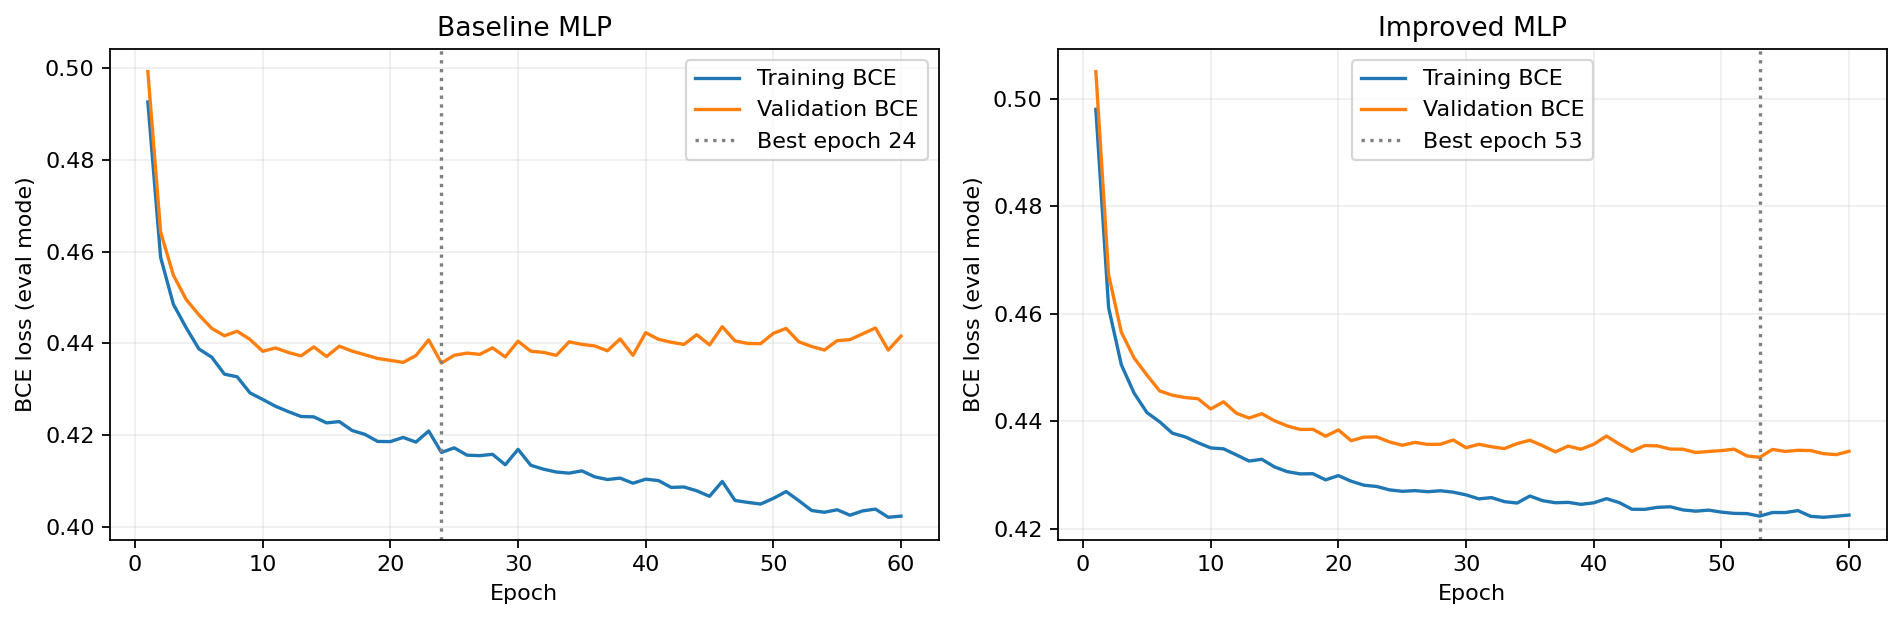

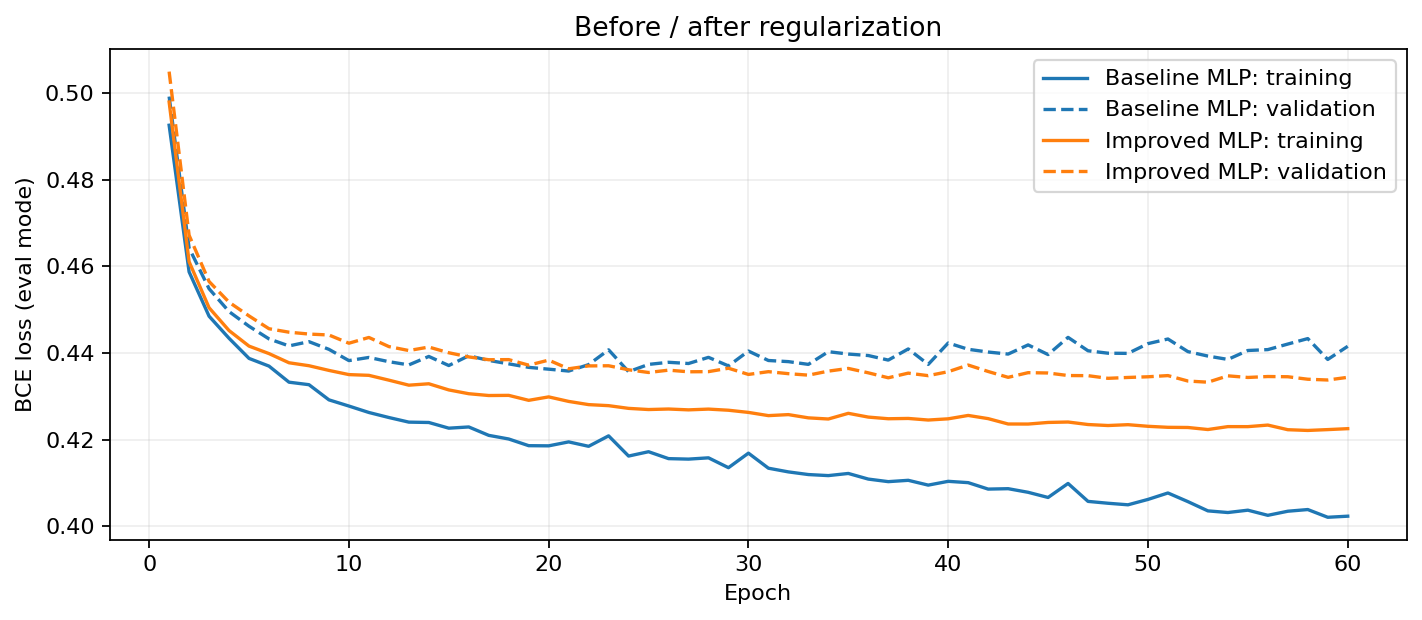

In [7]:
# 主目標：繪製並保存訓練／驗證 loss 圖。
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, history) in zip(axes, histories.items()):
    ax.plot(history["Epoch"], history["TrainingLoss"], label="Training BCE")
    ax.plot(history["Epoch"], history["ValidationLoss"], label="Validation BCE")
    ax.axvline(best_epochs[name], color="gray", linestyle=":", label=f"Best epoch {best_epochs[name]}")
    ax.set(xlabel="Epoch", ylabel="BCE loss (eval mode)", title=name)
    ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "loss_curves.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4))
for name, history in histories.items():
    line, = ax.plot(history["Epoch"], history["TrainingLoss"], label=f"{name}: training")
    ax.plot(history["Epoch"], history["ValidationLoss"], linestyle="--",
            color=line.get_color(), label=f"{name}: validation")
ax.set(xlabel="Epoch", ylabel="BCE loss (eval mode)", title="Before / after regularization")
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "loss_comparison.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)

## 8. 主目標：比較四個指標與混淆矩陣
兩者皆以最佳 checkpoint 輸出機率，且採相同 0.50 門檻。這份資料正類約 22%，
單看 Accuracy 容易忽略違約者的漏報，因此同時呈現 Recall、Precision、F1 與 FP／FN。

Positive label = 1; prediction = 1 when probability >= threshold


,Model,EpochsTrained,BestEpoch,TrainingLoss,ValidationLoss,Threshold,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Baseline MLP,60,24,0.4162,0.4357,0.5,0.8175,0.6518,0.3753,0.4763,4407,266,829,498
1,Improved MLP,60,53,0.4223,0.4333,0.5,0.8195,0.6704,0.3617,0.4699,4437,236,847,480


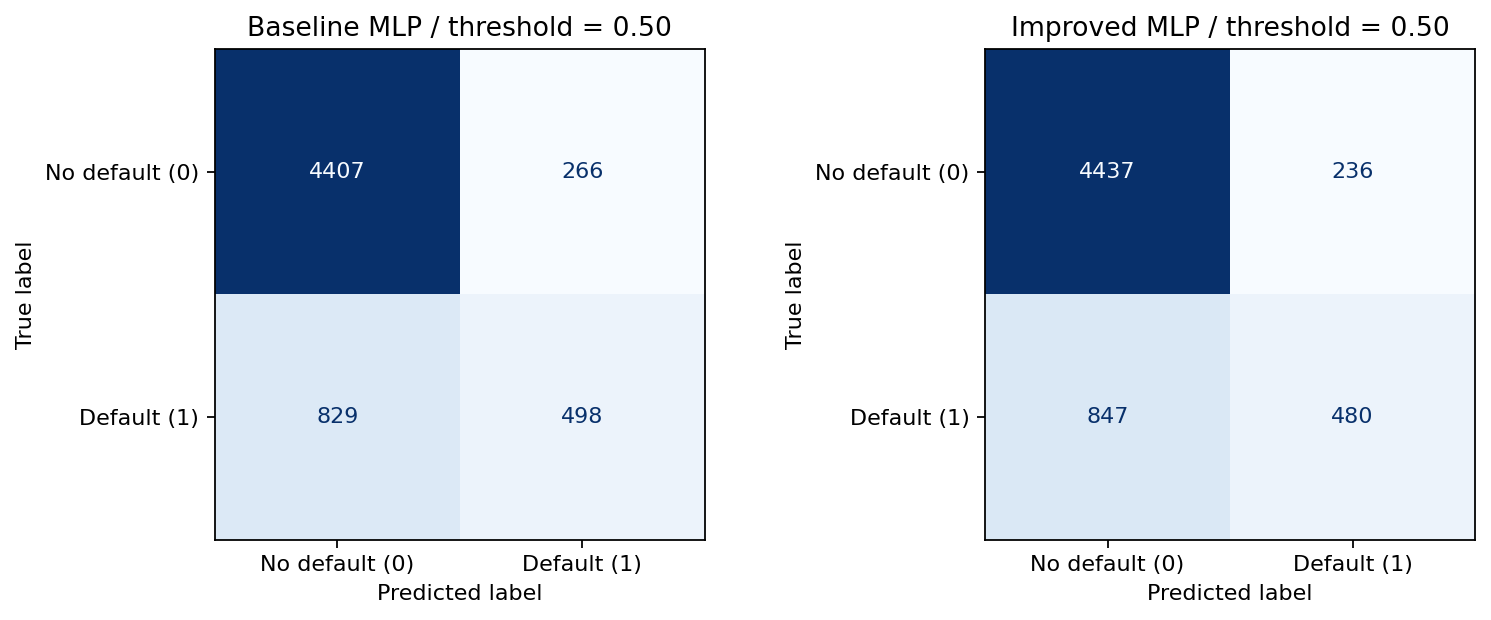

In [8]:
# 子目標：統一計算 Accuracy、Precision、Recall、F1，以及四種混淆矩陣計數。
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

def classification_metrics(y_true, probability, threshold=0.5):
    prediction = (np.asarray(probability) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

print("Positive label = 1; prediction = 1 when probability >= threshold")

comparison = []
for name, probability in probabilities.items():
    comparison.append({"Model": name, "EpochsTrained": len(histories[name]),
        "BestEpoch": best_epochs[name], **checkpoint_losses[name],
        **classification_metrics(y_val, probability, 0.5)})
metrics_df = pd.DataFrame(comparison)
metrics_df.to_csv(OUT / "classification_metrics.csv", index=False)
display(metrics_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, probability) in zip(axes, probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, probability >= 0.5,
        labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name} / threshold = 0.50")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)

## 9. 主目標：實際展示一筆 Validation Sample 的預測
從驗證集取第 1 筆，**重新做一次 forward**，不是只列出事先寫好的結果。
輸出 logit 經 sigmoid 轉換為違約機率，再以 0.50 門檻得到預測標籤。
機率是模型估計值，不代表經過校準的個人真實違約風險。

In [9]:
# 主目標：印出一筆驗證樣本的原始特徵、真實標籤與兩個模型的預測。
sample_i = 0
raw_row = int(val_idx[sample_i])
display(df.loc[[raw_row], ["ID"] + feature_names + [TARGET]])
sample_rows = []
for name, model in trained_models.items():
    model.eval()
    with torch.no_grad():
        logit = model(X_val_t[sample_i:sample_i+1])
        probability = float(torch.sigmoid(logit).item())
    assert np.isclose(probability, probabilities[name][sample_i], atol=1e-6)
    sample_rows.append({"Model": name, "ClientID": int(client_ids[raw_row]),
        "TrueLabel": int(y_val[sample_i]), "DefaultProbability": probability,
        "Threshold": 0.50, "PredictedLabel": int(probability >= 0.50)})
sample_df = pd.DataFrame(sample_rows)
display(sample_df.round(4))
sample_df.to_csv(OUT / "sample_prediction.csv", index=False)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
6907,6908,50000.0,1,2,2,46,-1,-1,-1,-1,0,0,1540.0,26060.0,0.0,2650.0,3320.0,2764.0,26060.0,0.0,3472.0,2320.0,1764.0,2841.0,0


,Model,ClientID,TrueLabel,DefaultProbability,Threshold,PredictedLabel
0,Baseline MLP,6908,0,0.1079,0.5,0
1,Improved MLP,6908,0,0.1185,0.5,0


## 10. 主目標：依實測結果撰寫觀察
把最佳 checkpoint 的效果、最後 epoch 的泛化差距與末 10 epochs 的波動分開比較。
只跑一個 seed，不能據此宣稱統計顯著或保證未來資料都有改善。
validation 集也參與最佳 checkpoint 選擇，這是驗證結果，不是獨立測試成績。

In [10]:
# 主目標：產生可核對數字的改善前後報告。
baseline = metrics_df.set_index("Model").loc["Baseline MLP"]
improved = metrics_df.set_index("Model").loc["Improved MLP"]
loss_delta = float(improved["ValidationLoss"] - baseline["ValidationLoss"])
diagnostics = []
for name, history in histories.items():
    last = history.iloc[-1]
    diagnostics.append({"Model": name,
        "FinalEpochTrainLoss": float(last["TrainingLoss"]),
        "FinalEpochValLoss": float(last["ValidationLoss"]),
        "FinalEpochGap": float(last["ValidationLoss"] - last["TrainingLoss"]),
        "Last10ValLossStd": float(history["ValidationLoss"].tail(10).std(ddof=0))})
diagnostic_df = pd.DataFrame(diagnostics).set_index("Model")
display(diagnostic_df.round(5))
diagnostic_df.to_csv(OUT / "overfitting_diagnostics.csv")
gap_delta = diagnostic_df.loc["Improved MLP", "FinalEpochGap"] - diagnostic_df.loc["Baseline MLP", "FinalEpochGap"]
stability_delta = diagnostic_df.loc["Improved MLP", "Last10ValLossStd"] - diagnostic_df.loc["Baseline MLP", "Last10ValLossStd"]
lines = ["### 實測觀察",
    f"- 原始與改良模型各完成 60 epochs；最佳 checkpoint 分別是 epoch {int(baseline['BestEpoch'])} 與 {int(improved['BestEpoch'])}。",
    f"- 最佳 checkpoint 的 validation BCE：原始 {baseline['ValidationLoss']:.5f} → 改良 {improved['ValidationLoss']:.5f}；差值 {loss_delta:+.5f}（負值才代表下降）。"]
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    lines.append(f"- {metric}：{baseline[metric]:.4f} → {improved[metric]:.4f}，差值 {improved[metric]-baseline[metric]:+.4f}。")
lines.extend([
    f"- 最後 epoch 的 validation−training loss 差距變化 {gap_delta:+.5f}；" + ("差距縮小，與較少過擬合的現象一致。" if gap_delta < 0 else "差距未縮小，不能宣稱此指標改善。"),
    f"- 末 10 epochs 的 validation loss 標準差變化 {stability_delta:+.5f}；" + ("這個波動指標較小。" if stability_delta < 0 else "這個波動指標未降低。"),
    "- Dropout 與 L2 不保證每個分類指標同時提高；本次比較只支持上述實測變化。",
    "- Quiz 3 固定沿用 Improved MLP 的最佳 checkpoint 機率與同一驗證集。",
])
report = "\n".join(lines)
display(Markdown(report))
_ = (OUT / "observations.md").write_text(report + "\n", encoding="utf-8")

,FinalEpochTrainLoss,FinalEpochValLoss,FinalEpochGap,Last10ValLossStd
Model,,,,
Baseline MLP,0.40230,0.44156,0.03925,0.00166
Improved MLP,0.42253,0.43439,0.01186,0.00050


### 實測觀察
- 原始與改良模型各完成 60 epochs；最佳 checkpoint 分別是 epoch 24 與 53。
- 最佳 checkpoint 的 validation BCE：原始 0.43569 → 改良 0.43326；差值 -0.00243（負值才代表下降）。
- Accuracy：0.8175 → 0.8195，差值 +0.0020。
- Precision：0.6518 → 0.6704，差值 +0.0186。
- Recall：0.3753 → 0.3617，差值 -0.0136。
- F1：0.4763 → 0.4699，差值 -0.0064。
- 最後 epoch 的 validation−training loss 差距變化 -0.02739；差距縮小，與較少過擬合的現象一致。
- 末 10 epochs 的 validation loss 標準差變化 -0.00116；這個波動指標較小。
- Dropout 與 L2 不保證每個分類指標同時提高；本次比較只支持上述實測變化。
- Quiz 3 固定沿用 Improved MLP 的最佳 checkpoint 機率與同一驗證集。

## 11. 測試：核對訓練長度與 Quiz 3 輸出
確認兩次訓練皆完整 60 epochs、loss 無 NaN、機率在 [0,1]，且保存的索引和標籤相同。

In [11]:
# 測試：確認基本要求與跨題資料一致性。
assert len(train_idx) == 24000 and len(val_idx) == 6000
assert len(np.unique(np.r_[train_idx, val_idx])) == len(df)
for name, history in histories.items():
    assert len(history) == 60 and history["Epoch"].tolist() == list(range(1, 61))
    assert np.isfinite(history[["TrainingLoss", "ValidationLoss"]].to_numpy()).all()
    probability = probabilities[name]
    assert probability.shape == y_val.shape and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    saved = torch.load(ART / model_files[name], map_location="cpu", weights_only=True)
    reloaded = MLP(saved["input_dim"], saved["hidden_dims"], saved["dropout"])
    reloaded.load_state_dict(saved["state_dict"])
    _, reloaded_probability = evaluate_loss_and_probability(reloaded, X_val_t, y_val_t)
    np.testing.assert_allclose(reloaded_probability, probability, atol=1e-7)
with np.load(ART / "credit_split.npz", allow_pickle=False) as split, np.load(ART / "mlp_validation_predictions.npz", allow_pickle=False) as pred:
    np.testing.assert_array_equal(split["val_idx"], pred["val_idx"])
    np.testing.assert_array_equal(split["y_val"], pred["y_val"])
    assert split["data_sha256"].item() == pred["data_sha256"].item() == data_sha256
print("PASS：兩個 MLP 各訓練 60 epochs；模型可還原，Quiz 3 所需輸出已保存。")

PASS：兩個 MLP 各訓練 60 epochs；模型可還原，Quiz 3 所需輸出已保存。
